# Section 1 - Imports

In [1]:
import pandas as pd ## Importing pandas for data handling
import numpy as np ## Importing numpy for calulations
import matplotlib.pyplot as plt ## Importing matplotlib for plotting
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
import seaborn as sns
colors = sns.color_palette() 

# Section 2 - Load and inspect the data 

In [2]:
df = pd.read_csv("data/raw/day.csv")
dateday = pd.to_datetime(df["dteday"])
df = df.set_index(dateday)


# Section 3 - Feature Engineering

In [3]:
df["time_years"] = (df["instant"] - 1) / 365
weather = pd.get_dummies(df["weathersit"], prefix="weather",dtype=float,drop_first=True)
weather = weather.rename(columns = {"weather_2": "weather_mist", "weather_3" : "weather_rain"})
X = pd.DataFrame(list(zip(df["temp"],df["workingday"],df["time_years"],weather["weather_mist"],weather["weather_rain"])))
y = df["cnt"]
print(y.shape)
print(X.shape)



(731,)
(731, 5)


# Section 4 Train/Validation/Test split
Data set contains 731 observations,

* 80% for training

* 20% for test

* Fit = 80% of training data
* Validation = 20% of training data

Check so that this is satisfied


* Fit - 467 days
* Validation - 117 days
* Test 147 days 

In [4]:
split_index = int(df.shape[0] * 0.8 ) # Calulating where to do the first split into training and test

## Splitting the features ie the X values
## Traning data
X_training = X.iloc[:split_index]
## Splitting into fit and val
split_index_fit_val = int(X_training.shape[0] * 0.8)
X_fit = X_training.iloc[:split_index_fit_val]
X_val = X_training.iloc[split_index_fit_val:]
#Testing data
X_test = X.iloc[split_index:]

# Splitting the actual values ie the y values 
y_training = y.iloc[:split_index]
## Splitting into fit and val
y_fit = y_training.iloc[:split_index_fit_val]
y_val = y_training.iloc[split_index_fit_val:]


y_test = y.iloc[split_index:]




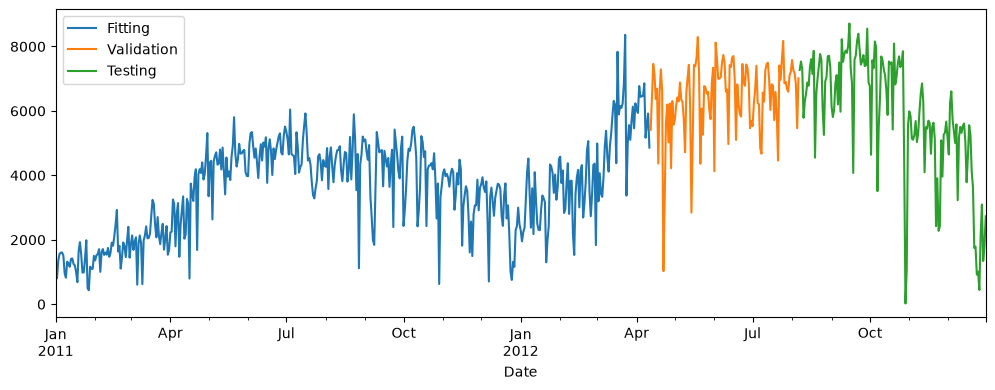

In [5]:
fig, ax = plt.subplots(figsize=(12,4))

y_fit.plot(ax=ax, label = "Fitting")
y_val.plot(ax=ax, label="Validation")
y_test.plot(ax=ax, label="Testing")
plt.xlabel("Date")
plt.legend()

plt.show()

# Section 5 Evaluation functions 

In [6]:
def mse_rmse_calc(predictions, actual, mse_or_rmse):
    if type(predictions) == pd.Series or type(predictions) == pd.DataFrame :
        predictions = predictions.to_numpy()
    if type(actual) == pd.Series or type(actual) == pd.DataFrame :
        actual = actual.to_numpy()
    mse = ((predictions - actual)**2).mean()
    rmse = np.sqrt(mse)
    if mse_or_rmse == "MSE":
        return mse
    if mse_or_rmse == "RMSE":
        return rmse 
    

# Section 6 Model experiments  

## Linear Regression Model

In [7]:
linear_model = LinearRegression()

linear_model.fit(X_fit,y_fit)

predictions_linear = linear_model.predict(X_val)



print(f": MSE {mse_rmse_calc(predictions_linear, y_val, "MSE")}")
print(f": RMSE {mse_rmse_calc(predictions_linear, y_val, "RMSE")}")

: MSE 1247608.4193441032
: RMSE 1116.9639292940947


## Decision Tree 

In [8]:
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)

tree_model.fit(X_fit,y_fit)

predictions_tree = tree_model.predict(X_val)

print(f": MSE {mse_rmse_calc(predictions_tree, y_val, "MSE")}")
print(f": RMSE {mse_rmse_calc(predictions_tree, y_val, "RMSE")}")

: MSE 1308024.093616453
: RMSE 1143.6888097802012


## Gradient Boosting 

In [9]:
gb_model = GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, max_depth=2, random_state=42)

gb_model.fit(X_fit,y_fit)

predictions_gb = gb_model.predict(X_val)

print(f": MSE {mse_rmse_calc(predictions_gb, y_val, "MSE")}")
print(f": RMSE {mse_rmse_calc(predictions_gb, y_val, "RMSE")}")

: MSE 847484.6877757858
: RMSE 920.589315479919


## XGBoost 

In [10]:
xgb_model = XGBRegressor(n_estimators = 50, learning_rate = 0.1, max_depth = 2, reg_lambda = 1, random_state = 42 )

xgb_model.fit(X_fit,y_fit)

predictions_xgb = xgb_model.predict(X_val)

print(f": MSE {mse_rmse_calc(predictions_xgb, y_val, "MSE")}")
print(f": RMSE {mse_rmse_calc(predictions_xgb, y_val, "RMSE")}")

: MSE 858898.000044491
: RMSE 926.7675005331655


# Section 7 - Hyperparameter tuning 

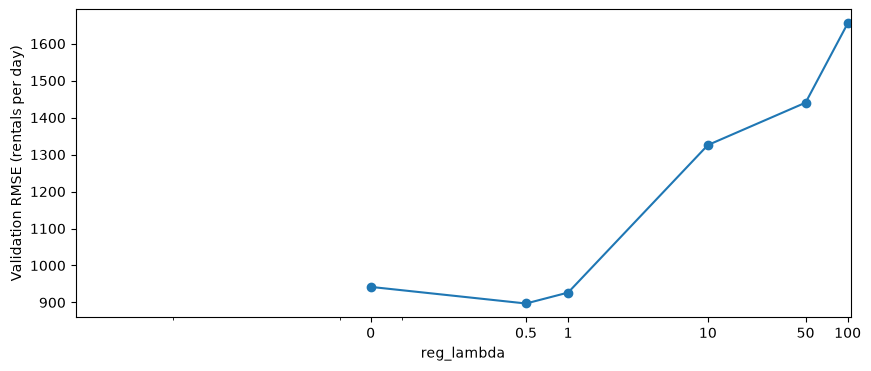

Best reg_lambda: 0.5
Best XGBoost validation RMSE: 897.21


In [11]:
strengths = [0, 0.5, 1, 10, 50, 100]
results = []

for strength in strengths:
    xgb_model = XGBRegressor(
        n_estimators=50,
        learning_rate=0.1,
        max_depth=2,
        reg_lambda=strength,
        random_state=42,
    )

    xgb_model.fit(X_fit, y_fit)
    predictions = xgb_model.predict(X_val)
    results.append(mse_rmse_calc(predictions, y_val, "RMSE"))

results_strengths = pd.Series(results, index=strengths)
best_strength = results_strengths.idxmin()

fig, ax = plt.subplots(figsize=(10, 4))
results_strengths.plot(ax=ax, marker="o")
ax.set_xscale("symlog", linthresh=0.5)
ax.set_xticks(strengths, labels=[str(value) for value in strengths])
ax.set_xlabel("reg_lambda")
ax.set_ylabel("Validation RMSE (rentals per day)")
plt.show()

print(f"Best reg_lambda: {best_strength:g}")
print(f"Best XGBoost validation RMSE: {results_strengths.min():.2f}")

# Section 8 - Results and conclusions

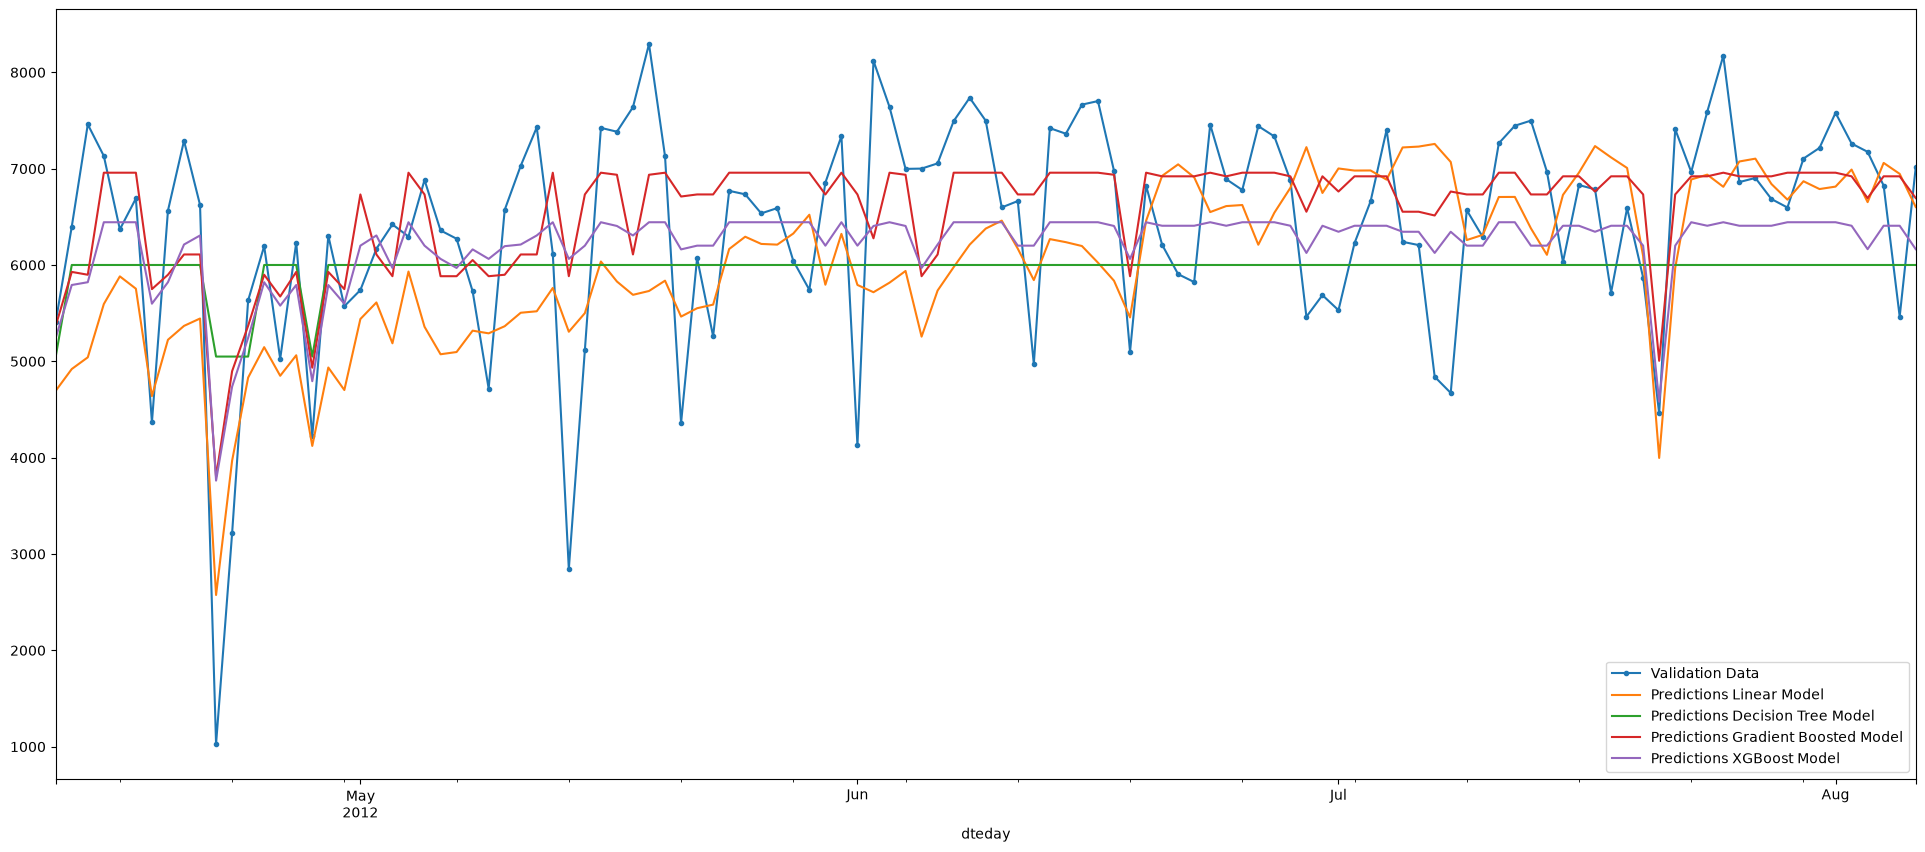

In [12]:
predictions_linear = pd.Series(predictions_linear, index=y_val.index)
predictions_tree = pd.Series(predictions_tree, index=y_val.index)
predictions_gb = pd.Series(predictions_gb, index=y_val.index)
predictions_xgb = pd.Series(predictions_xgb, index=y_val.index)

fig, ax = plt.subplots(figsize=(24,10))

y_val.plot(ax=ax, label="Validation Data",style=".-")
predictions_linear.plot(ax=ax, label="Predictions Linear Model")
predictions_tree.plot(ax=ax, label="Predictions Decision Tree Model")
predictions_gb.plot(ax=ax, label="Predictions Gradient Boosted Model")
predictions_xgb.plot(ax=ax, label="Predictions XGBoost Model")


plt.legend()

plt.show()

In [13]:
from sklearn.base import clone

validation_rmse = pd.Series(
    {
        "Linear Regression": mse_rmse_calc(linear_model.predict(X_val), y_val, "RMSE"),
        "Decision Tree": mse_rmse_calc(tree_model.predict(X_val), y_val, "RMSE"),
        "Gradient Boosting": mse_rmse_calc(gb_model.predict(X_val), y_val, "RMSE"),
        "XGBoost": results_strengths.min(),
    }
).sort_values()

print(validation_rmse.round(2))

best_model_name = str(validation_rmse.idxmin())

models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Gradient Boosting": gb_model,
    "XGBoost": clone(xgb_model).set_params(reg_lambda=best_strength),
}

# Make a fresh copy so the original fitted model stays available.
final_model = clone(models[best_model_name])
final_model.fit(X_training, y_training)

predictions_test = final_model.predict(X_test)
test_rmse = mse_rmse_calc(predictions_test, y_test, "RMSE")

print(f"\nSelected model: {best_model_name}")
print(f"Test RMSE: {test_rmse:,.2f} rentals per day")

XGBoost               897.21
Gradient Boosting     920.59
Linear Regression    1116.96
Decision Tree        1143.69
dtype: float64

Selected model: XGBoost
Test RMSE: 1,241.42 rentals per day
